In [1]:
import perf
import pandas as pd

In [2]:
perf.system.info()

,cpu,core,numa,arch,platform,vendor,model,family,stepping,freq,L1i,L1d,L2,L3
0,0,0,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
1,1,4,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
2,2,8,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
3,3,12,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
4,4,16,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
5,5,20,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
6,6,28,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb
7,7,29,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb
8,8,30,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb
9,9,31,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb


In [3]:
perf.system.tune()

,setting,path,before,after
0,aslr,/proc/sys/kernel/randomize_va_space,off,off
1,governor,/sys/devices/system/cpu/cpu*/cpufreq/scaling_g...,performance,performance
2,energy_performance_preference,/sys/devices/system/cpu/cpu*/cpufreq/energy_pe...,performance,performance
3,cpu_frequency,/sys/devices/system/cpu/cpu*/cpufreq/scaling_{...,4.6GHz..4.6GHz;4.7GHz..4.7GHz;3.5GHz..3.5GHz,4.6GHz..4.6GHz;4.7GHz..4.7GHz;3.5GHz..3.5GHz
4,turbo,/sys/devices/system/cpu/intel_pstate/no_turbo,on,on
5,turbo_msr,/dev/cpu/*/msr,,on
6,boost,/sys/devices/system/cpu/cpufreq/boost,,on
7,rdpmc,/sys/devices/*/rdpmc,,
8,smt,/sys/devices/system/cpu/smt/control,on,on
9,nmi_watchdog,/proc/sys/kernel/nmi_watchdog,off,off


In [4]:
%%writefile /tmp/fizz_buzz.cpp

[[nodiscard]] auto fizz_buzz(int n) -> const char* {
    if (n % 15 == 0) return "FizzBuzz";
    if (n % 3 == 0)  return "Fizz";
    if (n % 5 == 0)  return "Buzz";
    return "Unknown";
}

Overwriting /tmp/fizz_buzz.cpp


In [5]:
!g++ -O3 -c /tmp/fizz_buzz.cpp -o /tmp/fizz_buzz.o

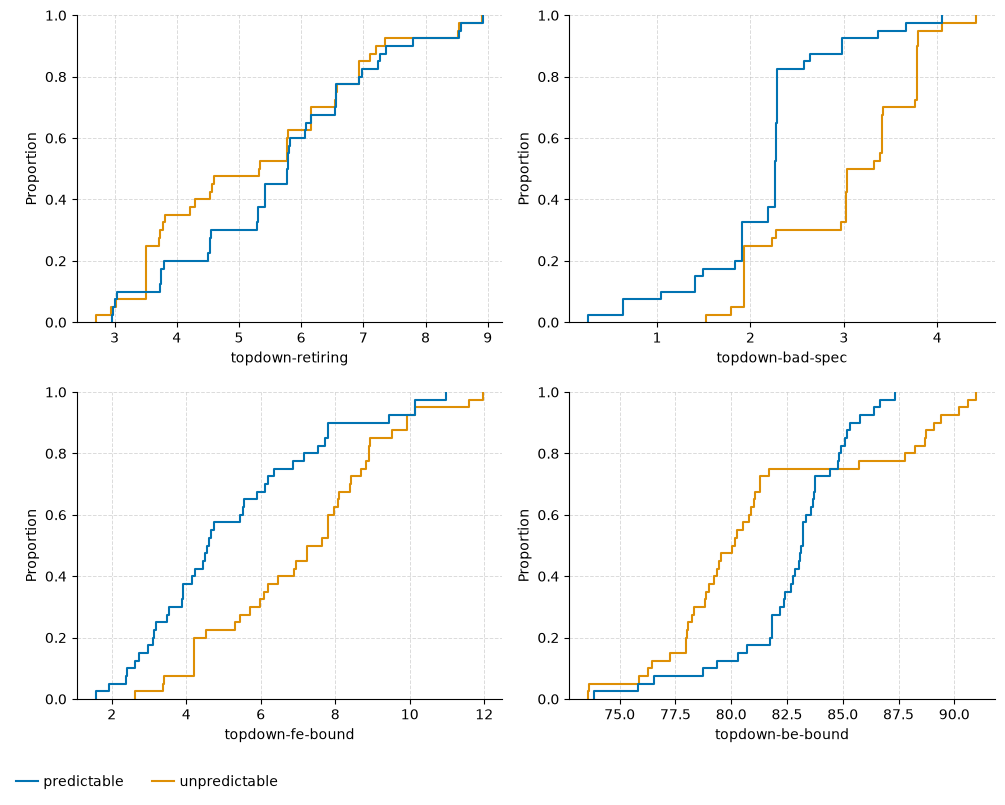

[]

In [6]:
df = perf.benchmark(symbol=["/tmp/fizz_buzz.o", "fizz_buzz"], mode=["latency"], event=["topdown*"])
perf.plot(df, "ecdf", groupby="config.branch")

In [7]:
btb = perf.benchmark(
    symbol=['/tmp/fizz_buzz.o', "fizz_buzz"],
    mode=["latency"],
    event=["cycles", "instructions", "branch-misses"],
)
summary = btb.groupby("config.branch")[["cycles", "instructions", "branch-misses"]].mean()
penalty = summary.loc["unpredictable"] - summary.loc["predictable"]
summary.loc["penalty"] = penalty
summary.round(2)

,cycles,instructions,branch-misses
config.branch,,,
predictable,5.36,15.75,0.18
unpredictable,20.43,15.72,0.56
penalty,15.07,-0.03,0.38


In [8]:
perf.analyze(symbol=['/tmp/fizz_buzz.o', "fizz_buzz"])

,index,file,name,address,encoding,size,latency,throughput,assembly,data.rdi
0,0,fizz_buzz.o@55dca1e3,fizz_buzz(int),4198720,f3 0f 1e fa,4,NaN,NaN,endbr64,"[1, 3, 15]"
1,1,fizz_buzz.o@55dca1e3,fizz_buzz(int),4198724,69 c7 ef ee ee ee,6,NaN,NaN,"imul eax, edi, 0xeeeeeeef","[1, 3, 15]"
2,2,fizz_buzz.o@55dca1e3,fizz_buzz(int),4198730,48 8d 15 b3 0e 00 00,7,1.0,0.2,"lea rdx, [rip + 0xeb3]","[1, 3, 15]"
3,3,fizz_buzz.o@55dca1e3,fizz_buzz(int),4198737,05 88 88 88 08,5,1.0,0.2,"add eax, 0x8888888","[1, 3, 15]"
4,4,fizz_buzz.o@55dca1e3,fizz_buzz(int),4198742,3d 10 11 11 11,5,1.0,0.2,"cmp eax, 0x11111110","[1, 3, 15]"
5,5,fizz_buzz.o@55dca1e3,fizz_buzz(int),4198747,76 3d,2,NaN,NaN,jbe .L40119a,"[1, 3, 15]"
6,6,fizz_buzz.o@55dca1e3,fizz_buzz(int),4198749,69 c7 ab aa aa aa,6,NaN,NaN,"imul eax, edi, 0xaaaaaaab","[1, 3]"
7,7,fizz_buzz.o@55dca1e3,fizz_buzz(int),4198755,48 8d 15 a3 0e 00 00,7,1.0,0.2,"lea rdx, [rip + 0xea3]","[1, 3]"
8,8,fizz_buzz.o@55dca1e3,fizz_buzz(int),4198762,05 aa aa aa 2a,5,1.0,0.2,"add eax, 0x2aaaaaaa","[1, 3]"
9,9,fizz_buzz.o@55dca1e3,fizz_buzz(int),4198767,3d 54 55 55 55,5,1.0,0.2,"cmp eax, 0x55555554","[1, 3]"


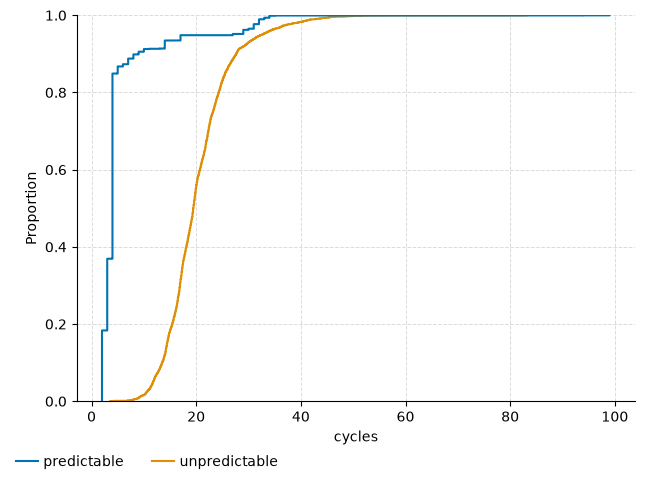

[]

In [9]:
perf.plot(btb, event="cycles", groupby="config.branch")